# Bloque C - C5: Criterios para identificar eritrocitos parasitados mediante color

**Objetivo:** definir el **criterio de color** para decidir si un eritrocito está parasitado, y estimar cómo funciona en un **paciente nuevo**. Es la estrategia "identificación mediante color" (8.1 del anteproyecto).

Comparamos dos tipos de criterio:
- **Reglas con umbrales** sobre las características de color de C4 (una característica, AND, OR, mayoría), con los umbrales ajustados en C5.
- **La regla de C3:** "la célula tiene al menos una mancha oscura de la máscara de C3".

**Criterio elegido: la regla de C3** (sección 6), por su mayor sensibilidad y su mejor rendimiento por paciente, aunque marca más células sanas que la mejor regla con umbrales.

**Cómo lo hacemos (solo con train):**
- Trabajamos con los **eritrocitos del GT de train** (parasitados y sanos). Los glóbulos blancos no entran: el Bloque A los excluye antes.
- Validamos con **leave-one-patient-out**: en cada vuelta se deja afuera un paciente y **se recalcula solo con los otros 5**:
  1. la **referencia de normalización** por fondo;
  2. los **rangos de color** de C4 (umbral "oscuro"/"violeta" e intervalos de los histogramas), y con ellos **todas las características**;
  3. la **selección de características** (misma regla que C4: AUC por paciente ≥ 0.8 y |ρ| < 0.8);
  4. los **umbrales** de cada regla.
- Después se aplica la regla al paciente que quedó afuera y se miden las métricas del anteproyecto: TP, FP, FN, **precisión**, **sensibilidad**, **F1**, matriz de confusión y resultados **por paciente**. Agregamos especificidad y exactitud balanceada.

Así no se usa el CSV de C4 tal como está (que se calculó con los 6 pacientes), como se anotó en sus conclusiones.

**Lo que NO se recalcula:** los parámetros de la máscara de manchas de C3 (`PARAMS_C3`). Se eligieron en C3 usando los 6 pacientes de train, así que las características que dependen de la máscara (`n_manchas`, `contraste_G_mancha`, etc.) ya incorporan información de todos los pacientes, incluido el que se deja afuera en cada vuelta. Por eso esta validación **no es completamente independiente** para esas características: está condicionada por decisiones de desarrollo previas tomadas sobre train. En C3 la validación anidada mostró que esos parámetros son estables entre pacientes, así que no esperamos que el efecto sea grande, pero no lo podemos descartar.

Para la regla de C3 hacemos además una **comparación con validación independiente de los parámetros de C3** (sección 6): usamos, para cada paciente, los parámetros de la máscara que eligió la **validación anidada de C3 sin ese paciente**.

**Test no se usa.** Queda para la evaluación final, con el criterio que se elija acá.

In [1]:
# BLOQUE C - C5: Criterios de color para identificar eritrocitos parasitados (solo train)

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve

from common.config import LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen
from common.generar_gt_utils import celulas_desde_gt
from segmentation.preprocess import mascara_circular

# Funciones del Bloque C (se importan, no se modifican)
from color_stain.normalizacion import mediana_fondo, normalizar_fondo, cargar_referencia
from color_stain.color_features import calcular_rangos, caracteristicas_color, cargar_rangos, manchas_c3, PARAMS_C3

CARPETA_RESULTADOS = Path("results")
COLOR_CLASE = {LABEL_UNINFECTED: "#eb6834", LABEL_PARASITIZED: "#1baf7a"}  # mismos colores que C1 y C4

AUC_MIN = 0.8   # misma regla de selección que C4
RHO_MAX = 0.8

## 1. Datos: recortes de train sin normalizar

Guardamos el recorte **sin normalizar** de cada célula de train y el fondo de su imagen. Así, en cada vuelta de la validación se puede normalizar con una referencia distinta sin volver a cargar las imágenes.

In [2]:
fondos = {}
for reg in cargar_subset("train"):
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    fondos[reg["image_id"]] = mediana_fondo(img, mascara_circular(img))

celulas = [(meta, recorte, mascara) for meta, recorte, mascara in celulas_desde_gt("train")]
pacientes = sorted({meta["patient_id"] for meta, _, _ in celulas})

conteo = pd.DataFrame([{"paciente": m["patient_id"], "label": m["label"]} for m, _, _ in celulas])
print(conteo.groupby(["paciente", "label"]).size().unstack(fill_value=0))

label             Parasitized  Uninfected  White_Blood_Cell
paciente                                                   
208C67P28N_ThinF           21         457                 0
209C68P29N_ThinF          145         268                 3
211C70P31_ThinF            37         193                 4
212C71P32_ThinF             5         496                 0
263C115P76ThinF             5         486                 1
282C134P95ThinF             4         235                 2


## 2. Funciones de la validación

- `preparar_vuelta(pacientes_entreno)`: calcula la referencia de normalización y los rangos de color **solo con esos pacientes**, y con eso las características de **todas** las células (las de entrenamiento y las del paciente evaluado). Las características del paciente evaluado se calculan igual que se haría con un paciente nuevo: con parámetros que no lo conocen.
- `seleccionar(datos)`: ranking por AUC por paciente y selección "golosa", igual que en C4.
- `elegir_umbral(...)`: umbral de una característica con dos criterios posibles:
  - **Youden:** maximiza sensibilidad + especificidad.
  - **Máximo F1:** maximiza el F1 de la clase parasitada. Con ~10 sanas por cada parasitada, Youden tiende a marcar muchas sanas (baja la precisión); el F1 equilibra precisión y sensibilidad.

In [3]:
def preparar_vuelta(pacientes_entreno):
    # Referencia de normalización y rangos de color SOLO con los pacientes de entrenamiento; características de todas las células
    ref = np.mean([f for iid, f in fondos.items()
                   if any(m["image_id"] == iid and m["patient_id"] in pacientes_entreno for m, _, _ in celulas)], axis=0)
    normalizadas = [(meta, normalizar_fondo(recorte, fondos[meta["image_id"]], ref), mascara) for meta, recorte, mascara in celulas]
    rangos = calcular_rangos([(m["label"], r, k) for m, r, k in normalizadas if m["patient_id"] in pacientes_entreno])
    filas = []
    for meta, recorte, mascara in normalizadas:
        if meta["label"] == LABEL_WBC:
            continue  # el Bloque A excluye los glóbulos blancos antes de clasificar
        filas.append({"cell_id": meta["cell_id"], "patient_id": meta["patient_id"], "image_id": meta["image_id"],
                      "label": meta["label"],
                      **caracteristicas_color(recorte, mascara, rangos)})
    datos = pd.DataFrame(filas)
    datos["y"] = datos["label"] == LABEL_PARASITIZED
    return datos, ref, rangos


def columnas_caracteristicas(datos):
    return [c for c in datos.columns if c not in ["cell_id", "patient_id", "image_id", "label", "y", "n_pixeles"]]


def seleccionar(datos):
    # Ranking por AUC por paciente (media) y selección golosa, igual que C4. Devuelve [(característica, sentido)]
    filas = []
    for c in columnas_caracteristicas(datos):
        auc = roc_auc_score(datos["y"], datos[c])
        sentido = "mayor" if auc >= 0.5 else "menor"
        signo = 1 if sentido == "mayor" else -1
        auc_pac = [roc_auc_score(d["y"], signo * d[c]) for _, d in datos.groupby("patient_id")]
        filas.append({"caracteristica": c, "sentido": sentido, "auc_paciente": np.mean(auc_pac)})
    ranking = pd.DataFrame(filas).sort_values("auc_paciente", ascending=False)
    corr = datos[ranking["caracteristica"]].corr(method="spearman")
    elegidas = []
    for _, f in ranking.iterrows():
        if f["auc_paciente"] >= AUC_MIN and all(abs(corr.loc[f["caracteristica"], e]) < RHO_MAX for e, _ in elegidas):
            elegidas.append((f["caracteristica"], f["sentido"]))
    return elegidas


def puntaje(x, sentido):
    # Convierte la característica a "más alto = más sospechoso"
    return np.asarray(x, dtype=float) if sentido == "mayor" else -np.asarray(x, dtype=float)


def elegir_umbral(y, x, sentido, criterio):
    s = puntaje(x, sentido)
    if criterio == "Youden":
        fpr, tpr, umbrales = roc_curve(y, s)
        return umbrales[np.argmax(tpr - fpr)]
    precision, sensibilidad, umbrales = precision_recall_curve(y, s)
    f1 = 2 * precision[:-1] * sensibilidad[:-1] / np.maximum(precision[:-1] + sensibilidad[:-1], 1e-12)
    return umbrales[np.argmax(f1)]

## 3. Las reglas que comparamos

Con las características seleccionadas en cada vuelta (ordenadas de mejor a peor), probamos cuatro reglas de decisión, como propone el anteproyecto (umbrales y operadores lógicos):

| Regla | Una célula es **parasitada** si… |
|---|---|
| **1 característica** | la mejor característica supera su umbral |
| **2 con AND** | las dos mejores superan su umbral |
| **2 con OR** | al menos una de las dos mejores supera su umbral |
| **Mayoría de 3** | al menos 2 de las 3 mejores superan su umbral |

Cada umbral se elige por separado, con Youden o con máximo F1. En total, 4 reglas × 2 criterios = 8 combinaciones.

**Regla de referencia:** además comparamos con la regla más simple posible, **"tiene al menos una mancha de C3"**. No ajusta ningún umbral en C5 (usa la máscara de C3 tal cual) y sirve para ver si combinar varias características realmente mejora respecto de usar solo la máscara.

In [4]:
REGLAS = {
    "1 característica": (1, 1),   # (cuántas características usa, cuántas tienen que superar el umbral)
    "2 con AND": (2, 2),
    "2 con OR": (2, 1),
    "Mayoría de 3": (3, 2),
}
CRITERIOS = ["Youden", "Máximo F1"]


def ajustar_regla(entreno, elegidas, regla, criterio):
    n_usa, _ = REGLAS[regla]
    return [(c, s, elegir_umbral(entreno["y"], entreno[c], s, criterio)) for c, s in elegidas[:n_usa]]


def aplicar_regla(datos, umbrales, regla):
    _, n_minimo = REGLAS[regla]
    votos = sum(puntaje(datos[c], s) >= u for c, s, u in umbrales)
    return votos >= n_minimo


def metricas(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
    fn, tn = int((~pred & y).sum()), int((~pred & ~y).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    sens, espec = tp / (tp + fn), tn / (tn + fp)
    f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precisión": precision, "sensibilidad": sens,
            "especificidad": espec, "F1": f1, "exactitud balanceada": (sens + espec) / 2}

## 4. Validación leave-one-patient-out

Para cada uno de los 6 pacientes de train: se prepara la vuelta con los otros 5, se seleccionan las características, se ajustan los umbrales de cada regla y se predice el paciente que quedó afuera. Tarda unos minutos porque las características se recalculan en cada vuelta.

In [5]:
predicciones = []
seleccion_por_vuelta = []
caracteristicas_prueba = []  # características de cada célula calculadas en la vuelta en que su paciente quedó afuera
for paciente in pacientes:
    otros = [p for p in pacientes if p != paciente]
    datos, _, rangos = preparar_vuelta(otros)
    entreno = datos[datos["patient_id"] != paciente]
    prueba = datos[datos["patient_id"] == paciente]

    caracteristicas_prueba.append(prueba)

    # Regla de referencia: tiene al menos una mancha de C3 (no ajusta nada)
    predicciones.append(pd.DataFrame({"regla": "Referencia: tiene mancha de C3", "criterio": "-", "paciente": paciente,
                                      "image_id": prueba["image_id"].values, "cell_id": prueba["cell_id"].values,
                                      "y": prueba["y"].values, "pred": (prueba["n_manchas"] >= 1).values}))

    elegidas = seleccionar(entreno)
    seleccion_por_vuelta.append({"paciente afuera": paciente, "seleccionadas": ", ".join(c for c, _ in elegidas),
                                 "oscuro (G <)": round(rangos["umbral_oscuro"]), "violeta (b <)": round(rangos["umbral_violeta"])})

    for regla in REGLAS:
        for criterio in CRITERIOS:
            umbrales = ajustar_regla(entreno, elegidas, regla, criterio)
            pred = aplicar_regla(prueba, umbrales, regla)
            predicciones.append(pd.DataFrame({"regla": regla, "criterio": criterio, "paciente": paciente,
                                              "image_id": prueba["image_id"].values, "cell_id": prueba["cell_id"].values,
                                              "y": prueba["y"].values, "pred": np.asarray(pred)}))

predicciones = pd.concat(predicciones, ignore_index=True)
caracteristicas_prueba = pd.concat(caracteristicas_prueba, ignore_index=True).set_index("cell_id")
pd.set_option("display.max_colwidth", None)  # para ver la lista completa de características
pd.DataFrame(seleccion_por_vuelta)

,paciente afuera,seleccionadas,oscuro (G <),violeta (b <)
0,208C67P28N_ThinF,"b_rel_p1, G_hist_0, contraste_G_mancha, a_desvio, a_p95, b_hist_3",125,126
1,209C68P29N_ThinF,"area_cromatica, b_rel_p1, contraste_G_mancha, G_rel_p1, S_desvio, a_desvio, b_desvio, frac_oscura, b_hist_1, b_hist_2, a_p95",131,129
2,211C70P31_ThinF,"a_desvio, contraste_G_mancha, b_rel_p1, G_rel_p1, G_hist_0, frac_violeta, b_desvio, a_p95, b_hist_2",126,126
3,212C71P32_ThinF,"G_hist_0, contraste_G_mancha, b_rel_p1, S_desvio, b_desvio, b_hist_2, a_p95, S_media",124,126
4,263C115P76ThinF,"contraste_G_mancha, G_rel_p1, a_desvio, b_hist_0, frac_oscura, a_media, b_p5, G_hist_2",126,125
5,282C134P95ThinF,"b_rel_p1, contraste_G_mancha, G_hist_0, a_desvio, b_hist_0, b_hist_2, a_p95",125,126


Arriba: qué características se eligieron en cada vuelta y los rangos de color recalculados. Si se repiten entre vueltas, la selección es **estable**.

### Resultados de las combinaciones

Mostramos dos tipos de métricas, que responden preguntas distintas:
- **Acumuladas:** sumamos TP, FP, FN y TN de los 6 pacientes evaluados (cada célula se predice una sola vez, cuando su paciente quedó afuera) y calculamos las métricas. Le dan más peso a los pacientes con más células (por ejemplo 209C68P29N, con 145 de las 217 parasitadas).
- **Por paciente:** se calculan dentro de cada paciente y se resumen con la **media** y el **peor paciente**. Pesan a todos los pacientes por igual, así que son las que mejor describen qué esperar de **un paciente nuevo**.

In [6]:
filas = []
for (regla, criterio), d in predicciones.groupby(["regla", "criterio"], sort=False):
    m = metricas(d["y"], d["pred"])
    por_paciente = [metricas(dp["y"], dp["pred"]) for _, dp in d.groupby("paciente")]
    m["exactitud bal. (acumulada)"] = m.pop("exactitud balanceada")
    filas.append({"regla": regla, "criterio": criterio, **m,
                  "exactitud bal. (media por paciente)": np.mean([x["exactitud balanceada"] for x in por_paciente]),
                  "F1 (peor paciente)": np.min([x["F1"] for x in por_paciente])})
resumen = pd.DataFrame(filas).sort_values("F1", ascending=False).reset_index(drop=True)
resumen.to_csv(CARPETA_RESULTADOS / "c5_resultados_lopo.csv", index=False)
resumen.round(3)

,regla,criterio,TP,FP,FN,TN,precisión,sensibilidad,especificidad,F1,exactitud bal. (acumulada),exactitud bal. (media por paciente),F1 (peor paciente)
0,Mayoría de 3,Máximo F1,204,27,13,2108,0.883,0.940,0.987,0.911,0.964,0.900,0.154
1,Referencia: tiene mancha de C3,-,213,40,4,2095,0.842,0.982,0.981,0.906,0.981,0.957,0.273
2,Mayoría de 3,Youden,212,51,5,2084,0.806,0.977,0.976,0.883,0.977,0.938,0.235
3,2 con AND,Youden,201,46,16,2089,0.814,0.926,0.978,0.866,0.952,0.930,0.267
4,2 con AND,Máximo F1,155,20,62,2115,0.886,0.714,0.991,0.791,0.852,0.857,0.182
5,1 característica,Máximo F1,202,144,15,1991,0.584,0.931,0.933,0.718,0.932,0.859,0.154
6,2 con OR,Máximo F1,208,158,9,1977,0.568,0.959,0.926,0.714,0.942,0.901,0.222
7,1 característica,Youden,212,178,5,1957,0.544,0.977,0.917,0.699,0.947,0.898,0.235
8,2 con OR,Youden,214,195,3,1940,0.523,0.986,0.909,0.684,0.947,0.914,0.240


## 5. Resultados de la mejor regla con umbrales

Entre las 8 combinaciones de reglas con umbrales (sin contar la de C3), tomamos la de **mayor F1 acumulado**, porque el F1 es la métrica del anteproyecto que tiene en cuenta a la vez cuántas parasitadas se detectan (sensibilidad) y cuántas de las marcadas lo son de verdad (precisión). En la sección 6 la comparamos con la regla de C3.

> **Ojo:** la misma validación se usa para **elegir** la combinación y para **estimar** su rendimiento, así que su F1 es algo optimista: es el de la estrategia que salió mejor entre 8. La evaluación final en test será independiente siempre que no se modifique nada después de ver sus resultados, pero también tendrá incertidumbre, porque test tiene solo 2 pacientes.

In [7]:
mejor = resumen[resumen["regla"].isin(REGLAS)].iloc[0]
REGLA_FINAL, CRITERIO_FINAL = mejor["regla"], mejor["criterio"]
print(f"Mejor regla con umbrales: {REGLA_FINAL} | umbral por {CRITERIO_FINAL}")

d = predicciones[(predicciones["regla"] == REGLA_FINAL) & (predicciones["criterio"] == CRITERIO_FINAL)]
por_paciente = pd.DataFrame([{"paciente": p, "parasitadas": int(dp["y"].sum()), "sanas": int((~dp["y"]).sum()),
                              **metricas(dp["y"], dp["pred"])} for p, dp in d.groupby("paciente")])
por_paciente.round(3)

print("\nResultados por imagen:")
por_imagen = pd.DataFrame([{"paciente": dp["paciente"].iloc[0], "imagen": iid, "parasitadas": int(dp["y"].sum()),
                            "sanas": int((~dp["y"]).sum()), **metricas(dp["y"], dp["pred"])}
                           for iid, dp in d.groupby("image_id")])
print(por_imagen.round(3).to_string(index=False))

Mejor regla con umbrales: Mayoría de 3 | umbral por Máximo F1

Resultados por imagen:
        paciente                  imagen  parasitadas  sanas  TP  FP  FN  TN  precisión  sensibilidad  especificidad    F1  exactitud balanceada
 211C70P31_ThinF IMG_20150813_130332.jpg           15     99  15   0   0  99      1.000         1.000          1.000 1.000                 1.000
 211C70P31_ThinF IMG_20150813_131330.jpg           22     94  21   2   1  92      0.913         0.955          0.979 0.933                 0.967
 212C71P32_ThinF IMG_20150813_162016.jpg            4    277   4   6   0 271      0.400         1.000          0.978 0.571                 0.989
 212C71P32_ThinF IMG_20150813_163120.jpg            1    219   1   0   0 219      1.000         1.000          1.000 1.000                 1.000
208C67P28N_ThinF IMG_20150819_115417.jpg            4    183   4   6   0 177      0.400         1.000          0.967 0.571                 0.984
208C67P28N_ThinF IMG_20150819_121456.jpg    

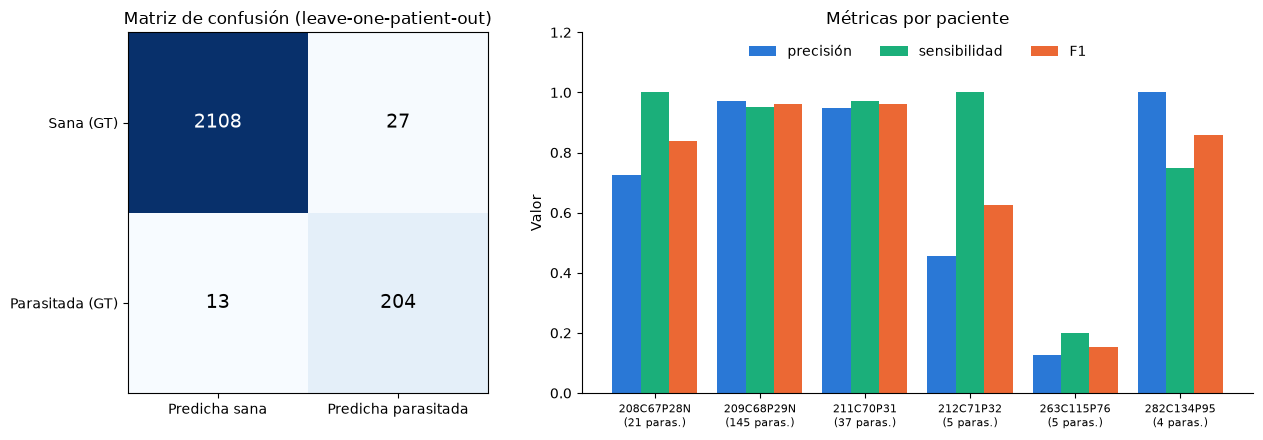

In [8]:
# Matriz de confusión acumulada (cada célula predicha cuando su paciente quedó afuera)
m = metricas(d["y"], d["pred"])
matriz = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, matriz[i, j], ha="center", va="center", fontsize=14,
                   color="white" if matriz[i, j] > matriz.max() / 2 else "black")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["Predicha sana", "Predicha parasitada"])
ax[0].set_yticks([0, 1])
ax[0].set_yticklabels(["Sana (GT)", "Parasitada (GT)"])
ax[0].set_title("Matriz de confusión (leave-one-patient-out)")

x = np.arange(len(por_paciente))
for k, (metrica, color) in enumerate([("precisión", "#2a78d6"), ("sensibilidad", "#1baf7a"), ("F1", "#eb6834")]):
    ax[1].bar(x + (k - 1) * 0.27, por_paciente[metrica].fillna(0), width=0.27, label=metrica, color=color)
ax[1].set_xticks(x)
ax[1].set_xticklabels([f"{p.split('_')[0].replace('ThinF', '')}\n({n} paras.)" for p, n in zip(por_paciente["paciente"], por_paciente["parasitadas"])], fontsize=8)
ax[1].set_ylim(0, 1.2)
ax[1].set_ylabel("Valor")
ax[1].set_title("Métricas por paciente")
ax[1].legend(frameon=False, loc="upper center", ncol=3)
ax[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Errores: falsos negativos y falsos positivos

Para entender en qué se equivoca la regla "mayoría de 3", mostramos los recortes de algunas células mal clasificadas (normalizados con la referencia de train), con la **máscara de C3 en verde** y los valores de sus 3 características. Arriba están **todos los falsos negativos del peor paciente (263C115P76)**; abajo, falsos negativos de otros pacientes y falsos positivos. Los valores son los calculados en la vuelta en que el paciente quedó afuera.

> No ajustamos los umbrales mirando estos errores: sería sobreajustar al peor paciente. La figura sirve solo para interpretar.

Falsos negativos: 13 (4 del paciente 263) | Falsos positivos: 27


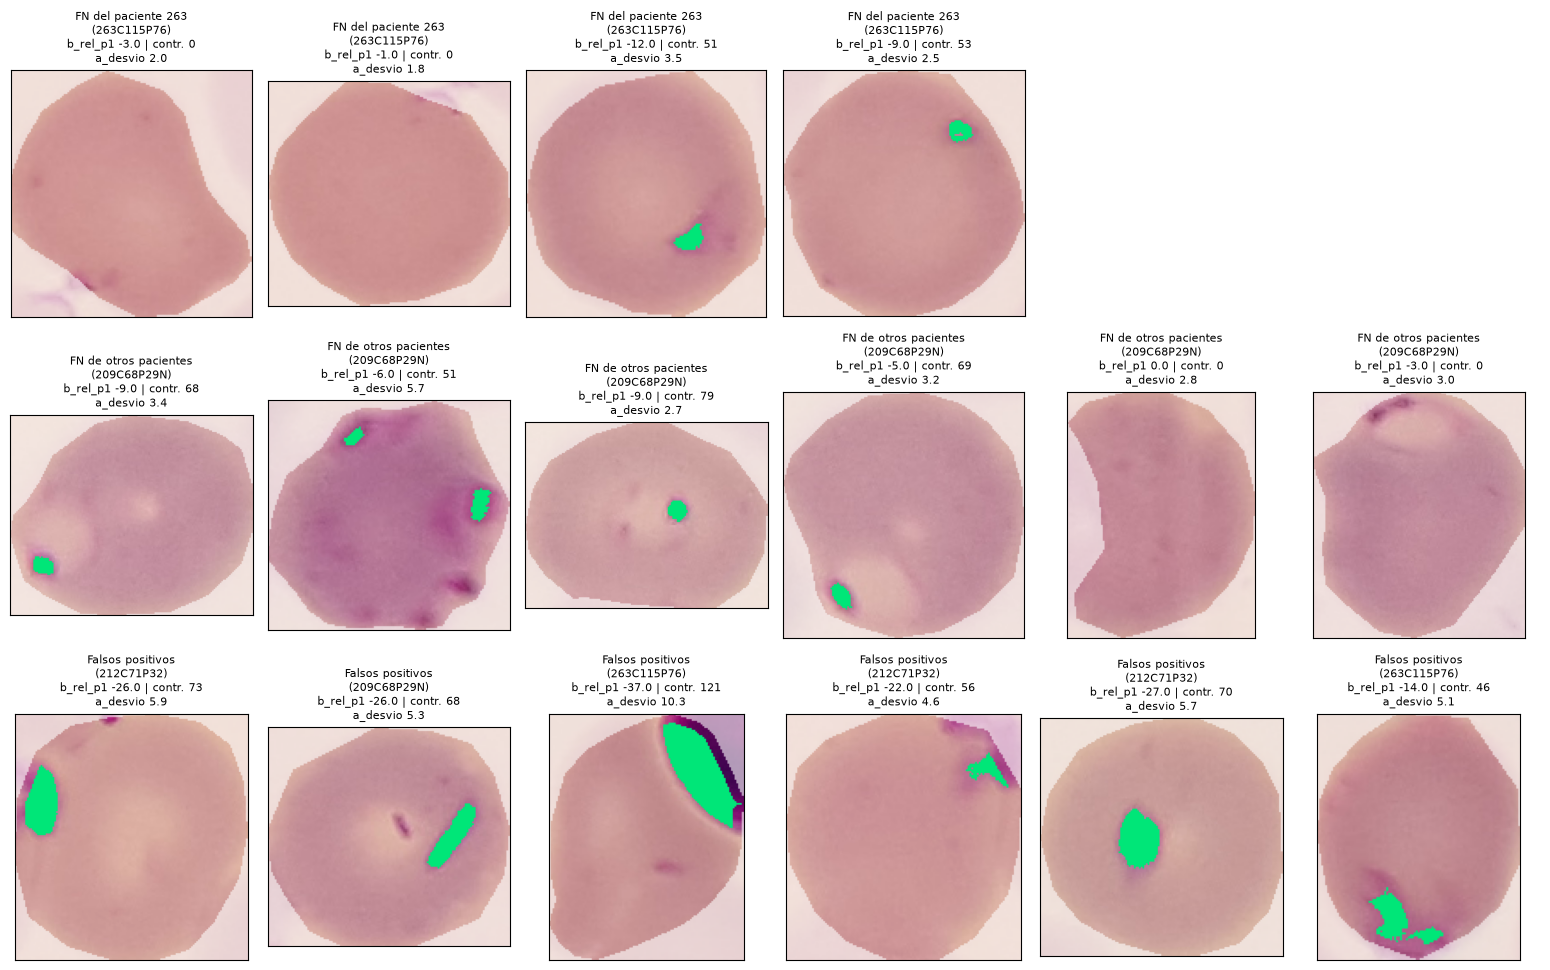

In [9]:
ref_train = cargar_referencia()
recortes = {meta["cell_id"]: (meta, recorte, mascara) for meta, recorte, mascara in celulas}


def mostrar(eje, cell_id, titulo):
    meta, recorte, mascara = recortes[cell_id]
    norm = normalizar_fondo(recorte, fondos[meta["image_id"]], ref_train)
    manchas, _ = manchas_c3(norm[:, :, 1], mascara, **PARAMS_C3)
    img = norm.copy()
    img[mascara == 0] = (img[mascara == 0] * 0.4 + 255 * 0.6).astype(np.uint8)
    img[manchas] = [0, 230, 120]
    f = caracteristicas_prueba.loc[cell_id]
    eje.imshow(img)
    eje.set_title(f"{titulo}\nb_rel_p1 {f['b_rel_p1']:.1f} | contr. {f['contraste_G_mancha']:.0f}\na_desvio {f['a_desvio']:.1f}", fontsize=8)
    eje.set_xticks([])
    eje.set_yticks([])


rng = np.random.default_rng(0)
fn = d[d["y"] & ~d["pred"]]
fp = d[~d["y"] & d["pred"]]
fn_263 = fn[fn["paciente"] == "263C115P76ThinF"]["cell_id"].tolist()
fn_otros = fn[fn["paciente"] != "263C115P76ThinF"]["cell_id"].tolist()
filas_fig = [
    ("FN del paciente 263", fn_263),
    ("FN de otros pacientes", list(rng.choice(fn_otros, size=min(6, len(fn_otros)), replace=False))),
    ("Falsos positivos", list(rng.choice(fp["cell_id"], size=min(6, len(fp)), replace=False))),
]
n_col = max(len(c) for _, c in filas_fig)
fig, ax = plt.subplots(len(filas_fig), n_col, figsize=(2.6 * n_col, 3.2 * len(filas_fig)), squeeze=False)
for fila, (nombre, ids) in enumerate(filas_fig):
    for col in range(n_col):
        if col < len(ids):
            pac = recortes[ids[col]][0]["patient_id"].split("_")[0].replace("ThinF", "")
            mostrar(ax[fila, col], ids[col], f"{nombre}\n({pac})")
        else:
            ax[fila, col].axis("off")
print(f"Falsos negativos: {len(fn)} ({len(fn_263)} del paciente 263) | Falsos positivos: {len(fp)}")
plt.tight_layout()
plt.show()

**Qué se ve en los errores:**
- **Falsos negativos del paciente 263C115P76:** en 2 de los 4 no se ve un parásito marcado: no hay mancha de C3 y `b_rel_p1` está cerca de 0, así que con color es prácticamente imposible detectarlos (parásitos muy tenues o muy chicos). En los otros 2 **sí hay una mancha de C3**, pero apenas por debajo de los umbrales (contraste 51-53 contra 56.5; `a_desvio` 2.5-3.5 contra 4.1): los parásitos de este paciente están **menos teñidos**, y la regla de "2 de 3" los rechaza.
- **Falsos negativos de otros pacientes** (casi todos de 209C68P29N): varios **tienen una mancha de C3 clara**, pero no alcanzan los umbrales de las otras dos características. Son células que la regla de C3 ("tiene mancha de C3") sí detecta: las otras dos condiciones terminan descartando parasitadas.
- **Falsos positivos:** son los mismos que vimos en C3: zonas oscuras en el **borde** de la célula (superposición con otra célula o con algo teñido) y objetos oscuros alargados encima de la célula, que podrían ser plaquetas o parásitos no anotados.

## 6. Comparación con la regla de C3 y elección del criterio

En la tabla de la sección 4, la regla **"tiene al menos una mancha de C3"** rinde parecido a la mayoría de 3. Pero esa comparación favorece a la regla de C3: usa los parámetros finales de la máscara, que se eligieron mirando los **6 pacientes**, y la regla depende **por completo** de esa máscara (la mayoría de 3, solo en una de sus condiciones).

Para compararlas con **validación independiente de los parámetros de C3**, aplicamos la regla de C3 con los parámetros que eligió la **validación anidada de C3 sin el paciente evaluado** (tabla de la sección 4 de C3), con la referencia de normalización también calculada sin ese paciente. Como control, los resultados por paciente tienen que coincidir con los de C3.

> Esta independencia es completa para la regla de C3, pero **no para la mayoría de 3**: sus características que dependen de la máscara (`contraste_G_mancha`) se calcularon con los parámetros finales de C3, elegidos con todo train. Así que la comparación no es del todo simétrica, y en todo caso favorece a la mayoría de 3.

In [10]:
# Parámetros de la máscara elegidos en la validación anidada de C3 SIN cada paciente (tabla de la sección 4 de C3)
# (modo, erosión, umbral, área mínima). En todas las vueltas el canal es G.
PARAMS_C3_ANIDADA = {
    "208C67P28N_ThinF": ("relativo", 0, -44, 25),
    "209C68P29N_ThinF": ("absoluto", 0, 106, 25),
    "211C70P31_ThinF": ("relativo", 5, -40, 50),
    "212C71P32_ThinF": ("relativo", 5, -41, 50),
    "263C115P76ThinF": ("relativo", 5, -52, 25),
    "282C134P95ThinF": ("relativo", 5, -42, 50),
}


def tiene_mancha_c3(recorte_norm, mascara, modo, erosion, umbral, area_min):
    # Misma máscara que C3 (con modo absoluto o relativo): ¿hay al menos una mancha de area_min píxeles?
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * erosion + 1, 2 * erosion + 1))
    dentro = cv2.erode(mascara, kernel) > 0 if erosion > 0 else mascara > 0
    verde = recorte_norm[:, :, 1].astype(np.int16)
    valores = verde - int(np.median(verde[dentro])) if modo == "relativo" else verde
    n, _, stats, _ = cv2.connectedComponentsWithStats(((valores < umbral) & dentro).astype(np.uint8), connectivity=8)
    return bool((stats[1:, cv2.CC_STAT_AREA] >= area_min).any())


filas_c3 = []
for paciente in pacientes:
    # Referencia de normalización sin el paciente (igual que en preparar_vuelta y en C3)
    ref = np.mean([f for iid, f in fondos.items()
                   if any(m["image_id"] == iid and m["patient_id"] != paciente for m, _, _ in celulas)], axis=0)
    for meta, recorte, mascara in celulas:
        if meta["patient_id"] != paciente or meta["label"] == LABEL_WBC:
            continue
        filas_c3.append({"regla": "Mancha de C3 (parámetros anidados)", "criterio": "-", "paciente": paciente,
                         "image_id": meta["image_id"], "cell_id": meta["cell_id"], "y": meta["label"] == LABEL_PARASITIZED,
                         "pred": tiene_mancha_c3(normalizar_fondo(recorte, fondos[meta["image_id"]], ref), mascara,
                                                 *PARAMS_C3_ANIDADA[paciente])})
pred_c3_anidada = pd.DataFrame(filas_c3)

# Control: exactitud balanceada por paciente (tiene que coincidir con la tabla de la sección 4 de C3)
print("Exactitud balanceada por paciente (control con C3):")
print(pred_c3_anidada.groupby("paciente").apply(lambda g: metricas(g["y"], g["pred"])["exactitud balanceada"]).round(3).to_string())

# Comparación de las tres versiones
versiones = {
    f"{REGLA_FINAL} ({CRITERIO_FINAL})": predicciones[(predicciones["regla"] == REGLA_FINAL) & (predicciones["criterio"] == CRITERIO_FINAL)],
    "Mancha de C3 (parámetros finales de C3)": predicciones[predicciones["regla"] == "Referencia: tiene mancha de C3"],
    "Mancha de C3 (parámetros anidados)": pred_c3_anidada,
}
filas_comp = []
for nombre, dv in versiones.items():
    m = metricas(dv["y"], dv["pred"])
    pp = [metricas(g["y"], g["pred"]) for _, g in dv.groupby("paciente")]
    filas_comp.append({"criterio": nombre, "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "precisión": m["precisión"],
                       "sensibilidad": m["sensibilidad"], "F1 (acumulado)": m["F1"],
                       "exactitud bal. (media por paciente)": np.mean([x["exactitud balanceada"] for x in pp]),
                       "F1 (peor paciente)": np.min([x["F1"] for x in pp])})
comparacion = pd.DataFrame(filas_comp).set_index("criterio")
comparacion.round(3)

Exactitud balanceada por paciente (control con C3):
paciente
208C67P28N_ThinF    0.987
209C68P29N_ThinF    0.946
211C70P31_ThinF     0.995
212C71P32_ThinF     0.992
263C115P76ThinF     0.789
282C134P95ThinF     1.000


,TP,FP,FN,precisión,sensibilidad,F1 (acumulado),exactitud bal. (media por paciente),F1 (peor paciente)
criterio,,,,,,,,
Mayoría de 3 (Máximo F1),204,27,13,0.883,0.940,0.911,0.900,0.154
Mancha de C3 (parámetros finales de C3),213,40,4,0.842,0.982,0.906,0.957,0.273
Mancha de C3 (parámetros anidados),214,60,3,0.781,0.986,0.872,0.951,0.316


Detalle por paciente de las dos opciones (la regla de C3 con parámetros anidados), y qué parasitadas pierde cada una:

In [11]:
mayoria = versiones[f"{REGLA_FINAL} ({CRITERIO_FINAL})"]
detalle = pd.concat({
    "Mayoría de 3": pd.DataFrame({p: metricas(g["y"], g["pred"]) for p, g in mayoria.groupby("paciente")}).T[["TP", "FP", "FN", "F1"]],
    "Mancha de C3 (anidada)": pd.DataFrame({p: metricas(g["y"], g["pred"]) for p, g in pred_c3_anidada.groupby("paciente")}).T[["TP", "FP", "FN", "F1"]],
}, axis=1)

fn_mayoria = set(mayoria.loc[mayoria["y"] & ~mayoria["pred"], "cell_id"])
fn_c3 = set(pred_c3_anidada.loc[pred_c3_anidada["y"] & ~pred_c3_anidada["pred"], "cell_id"])
print(f"Parasitadas que pierde la mayoría de 3: {len(fn_mayoria)} | la regla de C3: {len(fn_c3)} | las dos: {len(fn_mayoria & fn_c3)}")
detalle.astype(float).round(3)

Parasitadas que pierde la mayoría de 3: 13 | la regla de C3: 3 | las dos: 3


Mayoría de 3                  Mancha de C3 (anidada)        \
                           TP   FP   FN     F1                     TP    FP   
208C67P28N_ThinF         21.0  8.0  0.0  0.840                   21.0  12.0   
209C68P29N_ThinF        138.0  4.0  7.0  0.962                  144.0  27.0   
211C70P31_ThinF          36.0  2.0  1.0  0.960                   37.0   2.0   
212C71P32_ThinF           5.0  6.0  0.0  0.625                    5.0   8.0   
263C115P76ThinF           1.0  7.0  4.0  0.154                    3.0  11.0   
282C134P95ThinF           3.0  0.0  1.0  0.857                    4.0   0.0   

                              
                   FN     F1  
208C67P28N_ThinF  0.0  0.778  
209C68P29N_ThinF  1.0  0.911  
211C70P31_ThinF   0.0  0.974  
212C71P32_ThinF   0.0  0.556  
263C115P76ThinF   2.0  0.316  
282C134P95ThinF   0.0  1.000

**Qué se ve y qué elegimos:**
- **Control:** la exactitud balanceada por paciente coincide con la de la validación anidada de C3, así que la regla de C3 se está aplicando igual que allá.
- Con los **parámetros finales** de C3, la regla de C3 parecía empatar con la mayoría de 3 en F1 (0.906 contra 0.911). Con los **parámetros anidados** (validación independiente de los parámetros de C3) **pierde en F1 acumulado (0.872)**, porque marca **más del doble de células sanas** (60 contra 27), y la precisión baja de 0.883 a 0.781.
- En cambio, **gana en lo que importa para un paciente nuevo y para no perder infectadas:**
  - **pierde solo 3 parasitadas de 217**, contra 13 de la mayoría de 3, y las 3 también las pierde la mayoría de 3;
  - **exactitud balanceada media por paciente 0.951**, contra 0.900;
  - **F1 del peor paciente 0.316**, contra 0.154.
- **Por paciente:** la regla de C3 detecta **igual o más parasitadas en todos los pacientes**, pero marca más sanas en 4 de 6. En F1 por paciente gana en 211C70P31, 263C115P76 y 282C134P95, y pierde en 208C67P28N, 209C68P29N y 212C71P32. La mayor diferencia de falsos positivos está en **209C68P29N** (27 contra 4): su vuelta de C3 eligió el modo absoluto, y sus células son más oscuras en general. Como ese paciente tiene muchas células, pesa mucho en el F1 acumulado.

**Criterio elegido: la regla de C3 ("la célula tiene al menos una mancha oscura de la máscara de C3").**
- Prioriza **no perder eritrocitos parasitados** (sensibilidad 0.986), que en un diagnóstico de malaria es más grave que marcar de más.
- Es **más estable entre pacientes** (mejores métricas por paciente).
- Es **más simple y explicable**: mide directamente lo que se ve en el microscopio (una mancha oscura dentro del eritrocito) y no agrega umbrales ajustados en C5.
- El principal costo de priorizar la sensibilidad es el **aumento de falsos positivos** (precisión 0.78), que puede generar una **sobreestimación importante de la parasitemia**, especialmente en muestras con baja proporción de eritrocitos infectados. Hay que discutirlo en el informe.

Esta decisión se tomó **solo con train**, antes de mirar test.

## 7. Criterio final (ajustado con todo train)

El criterio final es la **regla de C3** con los **parámetros finales de C3**, elegidos con los 6 pacientes de train (`PARAMS_C3` de `color_features.py`: G relativo a la mediana de la célula, umbral −39, erosión 5, área mínima 50): **una célula es parasitada si tiene al menos una mancha** (`n_manchas ≥ 1`). Es lo que se aplicará, sin cambios, en la evaluación final sobre test y en el pipeline.

Se guarda en `results/c5_criterio_color.json`, junto con lo necesario para reproducirlo: la referencia de normalización y los parámetros de la máscara de C3. También dejamos documentada la alternativa descartada (mayoría de 3) con sus umbrales, para el informe. Comprobamos que la referencia coincide con `referencia_fondo.json`.

Al final mostramos el resultado de aplicar el criterio a las mismas células de train: es un resultado **sobre los datos de ajuste**, que sirve como referencia pero **no** estima el rendimiento en pacientes nuevos (para eso están las secciones 4 y 6).

In [12]:
datos_todo, ref_todo, rangos_todo = preparar_vuelta(pacientes)
assert np.allclose(ref_todo, cargar_referencia()), "La referencia no coincide con referencia_fondo.json"

# Alternativa descartada (mayoría de 3), ajustada con todo train, solo para documentarla
elegidas_mayoria = seleccionar(datos_todo)
umbrales_mayoria = ajustar_regla(datos_todo, elegidas_mayoria, REGLA_FINAL, CRITERIO_FINAL)

criterio = {
    "regla": "Tiene mancha de C3",
    "descripcion": "parasitada si la célula tiene al menos una mancha oscura de la máscara de C3 (n_manchas >= 1)",
    "params_mascara_c3": {"canal": "G", "modo": "relativo", **PARAMS_C3},
    "normalizacion_fondo_ref_rgb": [float(v) for v in ref_todo],
    "alternativa_descartada": {
        "regla": f"{REGLA_FINAL} ({CRITERIO_FINAL})",
        "minimo_que_superan": REGLAS[REGLA_FINAL][1],
        "condiciones": [f"{c} {'>=' if s == 'mayor' else '<='} {u if s == 'mayor' else -u:.4f}" for c, s, u in umbrales_mayoria],
        "rangos_color": rangos_todo,
    },
    "calculado_con": "train (6 pacientes)",
}
with open(CARPETA_RESULTADOS / "c5_criterio_color.json", "w") as archivo:
    json.dump(criterio, archivo, indent=2, ensure_ascii=False)

print("Criterio final:", criterio["descripcion"])
print("Parámetros de la máscara de C3:", criterio["params_mascara_c3"])
print("Alternativa descartada:", criterio["alternativa_descartada"]["regla"], "->", criterio["alternativa_descartada"]["condiciones"])

m_train = metricas(datos_todo["y"], (datos_todo["n_manchas"] >= 1).values)
print("\nSobre las mismas células de train (datos de ajuste, solo como referencia):")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in m_train.items()})

Criterio final: parasitada si la célula tiene al menos una mancha oscura de la máscara de C3 (n_manchas >= 1)
Parámetros de la máscara de C3: {'canal': 'G', 'modo': 'relativo', 'erosion': 5, 'umbral': -39, 'area_min': 50}
Alternativa descartada: Mayoría de 3 (Máximo F1) -> ['b_rel_p1 <= -8.6600', 'contraste_G_mancha >= 56.4616', 'a_desvio >= 4.0798']

Sobre las mismas células de train (datos de ajuste, solo como referencia):
{'TP': 213, 'FP': 40, 'FN': 4, 'TN': 2095, 'precisión': 0.842, 'sensibilidad': 0.982, 'especificidad': 0.981, 'F1': 0.906, 'exactitud balanceada': 0.981}


## 8. Conclusiones de C5

Los resultados son de **validación leave-one-patient-out sobre train**. Para las reglas con umbrales se recalcularon en cada vuelta, sin el paciente evaluado, la referencia de normalización, los rangos de color, las características, la selección y los umbrales; los parámetros de la máscara de C3 quedaron fijos (ver la limitación al principio). Para la regla de C3, la comparación de la sección 6 usa los parámetros de la validación anidada de C3, elegidos sin cada paciente (esa independencia es completa para la regla de C3, pero no para la mayoría de 3, cuyas características de la máscara usan los parámetros finales de C3). Test no se usó.

1. **Criterio elegido: "la célula tiene al menos una mancha oscura de la máscara de C3".** En la comparación con validación independiente de los parámetros de C3 (sección 6) detecta **214 de 217 parasitadas** (sensibilidad 0.986), con exactitud balanceada media por paciente **0.951** y F1 del peor paciente **0.316**. Su costo es marcar **60 de 2135 sanas** (precisión 0.781, F1 acumulado 0.872). Estos valores **no son el rendimiento garantizado del sistema final**: son sobre células delimitadas con el GT, y falta evaluarlo con la segmentación automática del Bloque A y, al final, con test.
2. **La mejor regla con umbrales** fue "mayoría de 3" con umbrales por máximo F1 (`b_rel_p1 ≤ −8.66`, `contraste_G_mancha ≥ 56.5`, `a_desvio ≥ 4.08`, al menos 2 de 3). Es **más precisa** (27 falsos positivos, precisión 0.883, F1 acumulado 0.911), pero **pierde 13 parasitadas** (sensibilidad 0.940) y rinde peor por paciente (exactitud balanceada media 0.900, F1 del peor paciente 0.154). Su F1 es además algo optimista, porque se eligió entre 8 combinaciones en la misma validación.
3. **Por qué elegimos la regla de C3:**
   - prioriza **no perder eritrocitos parasitados**, que en un diagnóstico de malaria es más grave que marcar de más: pierde 3 contra 13, y esas 3 también las pierde la mayoría de 3;
   - es **más estable entre pacientes**;
   - es **más simple y explicable**: mide directamente la mancha oscura que se ve en el microscopio y no agrega umbrales ajustados en C5.
   El principal costo de priorizar la sensibilidad es el **aumento de falsos positivos**, que puede generar una **sobreestimación importante de la parasitemia**, especialmente en muestras con baja proporción de eritrocitos infectados y en pacientes con células más oscuras, como 209C68P29N. Es una decisión de compromiso entre sensibilidad y precisión, tomada **solo con train**.
4. **Una sola característica de C4 no alcanza** (precisión 0.54-0.58), **OR** es la peor combinación y **AND** con máximo F1 pierde mucha sensibilidad (0.714). Combinar características de C4 no supera a la máscara de C3: casi toda la información útil está en la mancha oscura, y las otras condiciones terminan descartando parasitadas (ver la figura de errores).
5. **Métricas acumuladas vs. por paciente:** las acumuladas pesan más a los pacientes con muchas células (209C68P29N tiene 145 de las 217 parasitadas). Para un **paciente nuevo** importan más las métricas por paciente, que es donde la regla de C3 rinde mejor.
6. **Hay mucha variación entre pacientes e imágenes**, y depende de cuántas parasitadas tienen. El peor es **263C115P76** (5 parasitadas): la regla de C3 detecta 3 y la mayoría de 3, solo 1. En sus falsos negativos el parásito no se ve con color o está menos teñido. Con pocas células infectadas, unos pocos errores cambian mucho la **parasitemia**; conviene discutirlo en el informe.
7. **Criterio guardado** en `results/c5_criterio_color.json`: la regla de C3 con los parámetros finales de la máscara (G relativo, umbral −39, erosión 5, área mínima 50) y la referencia de normalización, para aplicarlo igual a células nuevas. Queda documentada la alternativa descartada (mayoría de 3) con sus umbrales.
8. **Limitaciones:**
   - los parámetros finales de C3 se eligieron con los 6 pacientes de train; la comparación de la sección 6 usa los de la validación anidada, que es la mejor estimación disponible para un paciente nuevo; esa independencia no es completa para la mayoría de 3;
   - en las reglas con umbrales, la máscara de C3 quedó fija, así que su validación no es completamente independiente para las características que dependen de ella;
   - todo es sobre las **células del GT**: con las células segmentadas por el Bloque A el rendimiento puede cambiar, y hay que evaluarlo en la integración;
   - test será una evaluación independiente si no se cambia nada después de verlo, pero con solo 2 pacientes va a tener bastante incertidumbre.

**Archivos generados (en `color_stain/results/`):**
- `c5_resultados_lopo.csv`: métricas de las 8 reglas con umbrales y de la regla de C3 con sus parámetros finales (sección 4).
- `c5_criterio_color.json`: el criterio final (regla de C3) con sus parámetros y la alternativa descartada.